# EDA 01 · Catálogo, precios y consumo

Primer vistazo, lo más simple posible:

1. **Qué categorías y subcategorías hay** (catálogo vigente = `shop.catalog` + último cambio de `shop.catalog_updates`).
2. **Precio por categoría y subcategoría** (boxplots).
3. **Consumo** a partir de las compras de `shop.history_events` (60 días): precio de lo comprado, gasto por usuario y ticket por sesión, por **dispositivo**, **región** y **categoría**.
4. Compras del carrusel por **página** (`history_sessions`) y patrón horario.

Los boxplots no muestran outliers y usan escala log en el precio, porque los precios van de 2 € a 640 €. Las horas están en UTC. Las figuras se guardan en `eda/fig/`.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

for p in [Path(".env"), Path("../.env"), Path("../datathon-fme-2026/.env")]:
    if p.exists():
        for line in p.read_text().splitlines():
            k, _, v = line.partition("=")
            if k.strip():
                os.environ.setdefault(k.strip(), v.strip())
        break
API = os.environ.get("RAWTREE_API_URL", "https://api.rawtree.com")
http = requests.Session()
http.headers["Authorization"] = f"Bearer {os.environ['RAWTREE_API_KEY']}"

def sql(q: str) -> pd.DataFrame:
    r = http.post(f"{API}/v1/query", json={"sql": q}, timeout=900)
    r.raise_for_status()
    return pd.DataFrame(r.json()["data"])

pd.set_option("display.max_rows", 200, "display.width", 200)
BLUE, INK, MUTED, GRID = "#2a78d6", "#1f2328", "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})
FIG = Path("fig"); FIG.mkdir(exist_ok=True)
eur = FuncFormatter(lambda v, _: f"{v:g} €")

def boxplot(df, by, col, title, xlabel="€", log=True, order=None, fname=None, ax=None, annotate=True):
    """Boxplot horizontal de `col` por grupo `by`, ordenado por mediana. Sin outliers."""
    order = order or df.groupby(by)[col].median().sort_values(ascending=False).index.tolist()
    data = [df.loc[df[by] == g, col].dropna().to_numpy() for g in order]
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 0.42 * len(order) + 1.1))
    bp = ax.boxplot(data, orientation="horizontal", showfliers=False, patch_artist=True, widths=0.55,
                    medianprops=dict(color=INK, linewidth=1.4), whiskerprops=dict(color=MUTED),
                    capprops=dict(color=MUTED), boxprops=dict(edgecolor=BLUE, linewidth=1))
    for b in bp["boxes"]:
        b.set_facecolor(BLUE); b.set_alpha(0.35)
    ax.set_yticks(range(1, len(order) + 1), order); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    if log:
        ax.set_xscale("log")
    if xlabel == "€":
        ax.xaxis.set_major_formatter(eur); ax.set_xlabel("")
    else:
        ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    if annotate:
        for i, d in enumerate(data, 1):
            if len(d):
                ax.text(1.01, i, f"med {np.median(d):.1f} · n={len(d):,}".replace(",", "."), transform=ax.get_yaxis_transform(),
                        va="center", fontsize=7.5, color=MUTED)
    if own:
        plt.tight_layout()
        if fname:
            plt.savefig(FIG / fname, bbox_inches="tight")
        plt.show()

## 1. Catálogo vigente: categorías y subcategorías

In [2]:
cat = sql("""
SELECT product_id,
       argMax(category, v) AS category, argMax(subcategory, v) AS subcategory, argMax(brand, v) AS brand,
       argMax(price_eur, v) AS price, argMax(is_active, v) AS is_active,
       max(is_new) AS is_new
FROM (
    SELECT product_id::String AS product_id, category::String AS category, subcategory::String AS subcategory,
           brand::String AS brand, price_eur::Float64 AS price_eur, is_active::Bool AS is_active, 0 AS is_new, '' AS v
    FROM shop.catalog
    UNION ALL
    SELECT product_id::String, category::String, subcategory::String, brand::String, price_eur::Float64, is_active::Bool,
           change::String = 'new_product', toString(ts)
    FROM shop.catalog_updates
)
GROUP BY product_id""")
cat["is_active"] = cat.is_active.astype(bool); cat["is_new"] = cat.is_new.astype(int).astype(bool)
print(f"{len(cat)} productos · {cat.category.nunique()} categorías · {cat.subcategory.nunique()} subcategorías · "
      f"{cat.brand.nunique()} marcas · {(~cat.is_active).sum()} sin stock ahora · {cat.is_new.sum()} nuevos del evento")

5100 productos · 10 categorías · 89 subcategorías · 80 marcas · 37 sin stock ahora · 100 nuevos del evento


In [3]:
resumen = (cat.groupby("category")
             .agg(productos=("product_id", "size"), subcategorias=("subcategory", "nunique"), marcas=("brand", "nunique"),
                  precio_mediana=("price", "median"), precio_min=("price", "min"), precio_max=("price", "max"),
                  sin_stock=("is_active", lambda s: int((~s).sum())), nuevos=("is_new", "sum"))
             .sort_values("productos", ascending=False))
resumen

,productos,subcategorias,marcas,precio_mediana,precio_min,precio_max,sin_stock,nuevos
category,,,,,,,,
Home & Garden,655,9,8,35.99,6.99,237.99,3,15
Pets,621,9,8,25.99,3.99,280.99,2,8
Electronics,591,9,8,30.99,2.99,485.99,4,11
Books & Media,564,9,8,29.49,1.99,629.99,9,11
Toys & Baby,527,8,8,37.99,4.99,354.99,4,11
Sports & Outdoors,495,9,8,18.99,2.99,399.99,3,6
Home & Kitchen,475,9,8,39.99,1.99,481.99,2,9
Computers & Gaming,437,9,8,31.99,3.99,257.99,3,10
Fashion,406,9,8,42.49,1.99,405.99,5,12


In [4]:
subcats = (cat.groupby(["category", "subcategory"])
             .agg(productos=("product_id", "size"), marcas=("brand", "nunique"),
                  p25=("price", lambda s: s.quantile(.25)), mediana=("price", "median"), p75=("price", lambda s: s.quantile(.75)),
                  sin_stock=("is_active", lambda s: int((~s).sum())), nuevos=("is_new", "sum"))
             .round(2))
subcats

productos  marcas     p25  mediana     p75  sin_stock  nuevos
category           subcategory                                                                    
Beauty & Health    Conditioner              14       7   42.99    51.49   79.24          0       0
                   Electric Shavers         21       8   21.99    29.99   37.99          0       0
                   Face Cream               21       8   31.99    40.99   58.99          0       0
                   Perfume                  35       8    8.99    11.99   14.99          1       3
                   Shampoo                  54       8    5.99     7.99   11.99          0       0
                   Shaver Blades            43       8  101.49   139.99  233.49          0       1
                   Sunscreen                16       7    4.99     6.99   10.24          0       0
                   Toothbrushes             41       8    8.99    14.99   17.99          1       0
                   Vitamins                 84       8   21.74    31.49   42.24          0       3
Books & Media      Comics                  109       8   14.99    22.99   31.99          1       2
                   Cookbooks                48       8   11.99    17.99   23.99          0       2
                   E-Reader Covers          32       7  159.74   253.99  296.49          1       0
                   E-Readers                75       8    3.99     4.99    5.99          1       1
                   Notebooks                37       8   19.99    27.99   36.99          1       2
                   Novels                   59       8   19.99    25.99   38.99          0       1
                   Travel Guides            88       8   52.74    70.99   96.24          1       1
                   Turntables               88       8   25.99    33.99   43.99          3       1
                   Vinyl Records            28       8  142.74   204.99  307.49          1       1
Computers & Gaming External Drives         108       8   14.99    21.49   28.99          0       4
                   Game Consoles            43       8   13.99    18.99   22.99          0       1
                   Gaming Headsets          68       8   24.74    36.49   47.24          1       1
                   Keyboards                92       8   32.74    45.99   63.24          0       0
                   Mice                     16       6   14.99    19.99   27.24          0       0
                   Monitors                 20       7   56.24    83.99  112.99          0       1
                   Routers                  37       8   23.99    30.99   45.99          1       2
                   Video Games              52       8   39.99    48.99   80.99          1       1
                   Webcams                   1       1   22.99    22.99   22.99          0       0
Electronics        Cameras                  13       6   34.99    38.99   58.99          1       0
                   Chargers                 65       8   27.99    37.99   52.99          1       2
                   Headphones               63       8   28.99    43.99   59.49          0       0
                   Laptop Sleeves          138       8   29.99    38.99   55.74          1       4
                   Laptops                  13       8    3.99     4.99    7.99          0       0
                   Phone Cases             182       8   14.99    19.99   25.99          0       3
                   Smartphones              24       8   15.99    16.99   25.99          0       2
                   Smartwatches             53       8   18.99    26.99   40.99          1       0
                   Tablets                  40       7   96.49   126.49  165.99          0       0
Fashion            Backpacks                22       8   15.99    17.99   22.99          0       0
                   Belts                    39       8   21.99    26.99   45.49          2       1
                   Jackets                  44       8    4.99     5.49    7.

## 2. Precio por categoría y por subcategoría

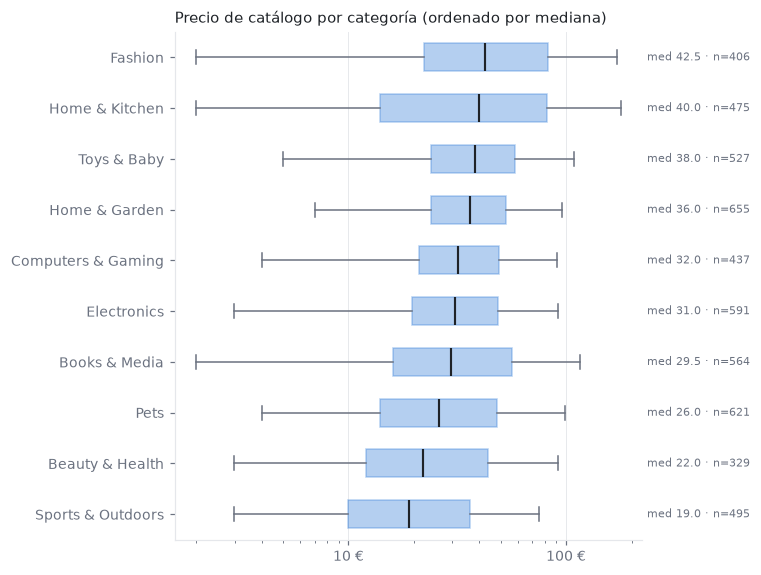

In [5]:
boxplot(cat, "category", "price", "Precio de catálogo por categoría (ordenado por mediana)", fname="precio_categoria.png")

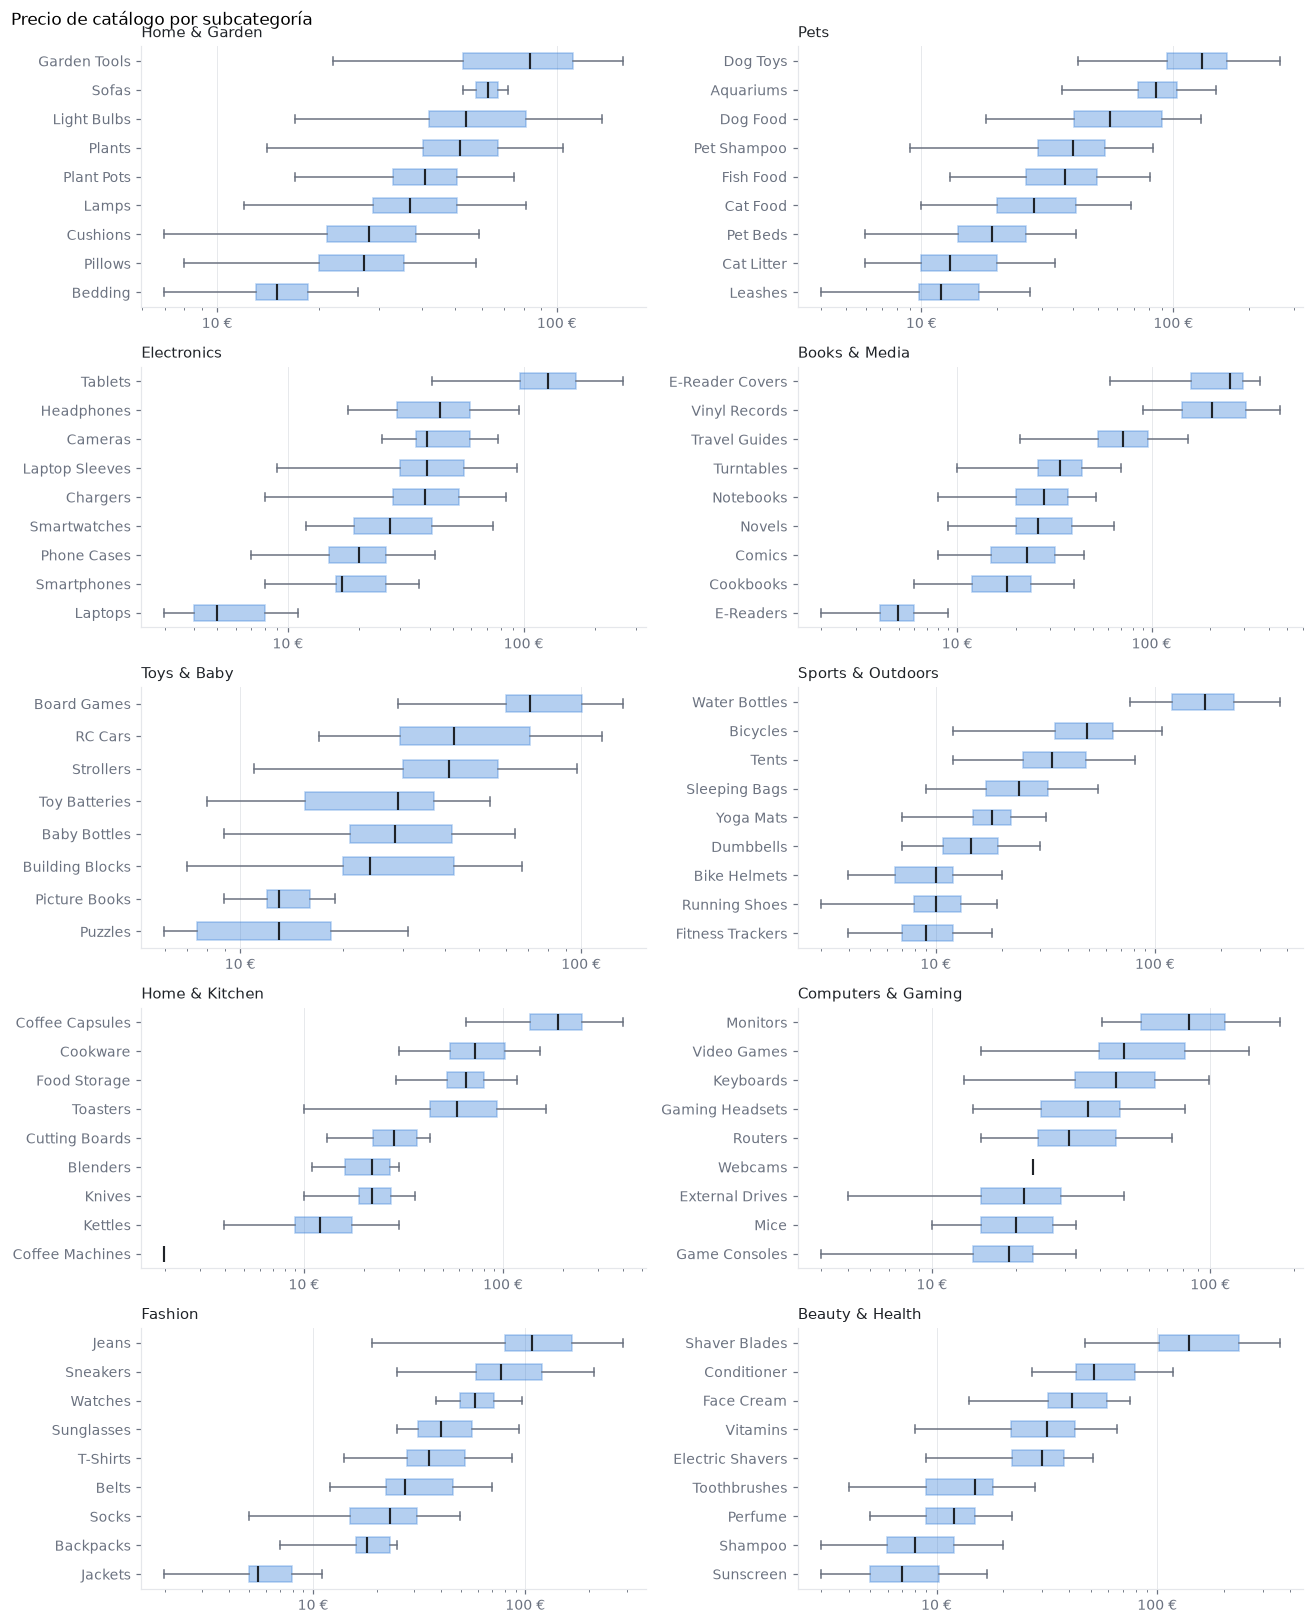

In [6]:
cats = resumen.index.tolist()
fig, axes = plt.subplots(5, 2, figsize=(12, 15))
for ax, c in zip(axes.flat, cats):
    boxplot(cat[cat.category == c], "subcategory", "price", c, ax=ax, annotate=False)
plt.suptitle("Precio de catálogo por subcategoría", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "precio_subcategoria.png", bbox_inches="tight"); plt.show()

### 2b. ¿Qué distribución sigue el precio?

Comparamos el precio con su logaritmo: asimetría, Shapiro-Wilk y Kolmogorov-Smirnov frente a una normal, por categoría y por subcategoría.

In [7]:
from scipy import stats
base = cat[~cat.is_new].copy()          # catálogo inicial (5.000)
base["log_price"] = np.log(base.price)
rows = []
for c, g in base.groupby("category"):
    z = (g.log_price - g.log_price.mean()) / g.log_price.std()
    rows.append({"category": c, "n": len(g), "asimetria": stats.skew(g.price), "asimetria_log": stats.skew(g.log_price),
                 "shapiro_p": stats.shapiro(g.price).pvalue, "shapiro_p_log": stats.shapiro(g.log_price).pvalue,
                 "ks_p_log": stats.kstest(z, "norm").pvalue})
dist = pd.DataFrame(rows).set_index("category").round(4)
sub_p = {s: (stats.shapiro(g.price).pvalue, stats.shapiro(g.log_price).pvalue) for s, g in base.groupby("subcategory") if len(g) >= 20}
sub_p = pd.DataFrame(sub_p, index=["p_precio", "p_log"]).T
print(f"Subcategorías con n>=20: {len(sub_p)} · normalidad NO rechazada (p>0,05): precio {(sub_p.p_precio > .05).mean():.0%} · log(precio) {(sub_p.p_log > .05).mean():.0%}")
print(f"Desv. típica de log(precio): dentro de subcategoría (mediana) {base.groupby('subcategory').log_price.std().median():.2f} · dentro de categoría (mediana) {base.groupby('category').log_price.std().median():.2f}")
print("Céntimos de los precios:", base.price.mod(1).round(2).value_counts().to_dict())
dist

Subcategorías con n>=20: 75 · normalidad NO rechazada (p>0,05): precio 12% · log(precio) 92%
Desv. típica de log(precio): dentro de subcategoría (mediana) 0.49 · dentro de categoría (mediana) 0.87
Céntimos de los precios: {0.99: 5000}


,n,asimetria,asimetria_log,shapiro_p,shapiro_p_log,ks_p_log
category,,,,,,
Beauty & Health,322,4.0334,0.4682,0.0,0.0001,0.1014
Books & Media,553,3.2890,0.0721,0.0,0.0002,0.1099
Computers & Gaming,427,2.3986,0.1049,0.0,0.6127,0.6408
Electronics,580,4.0515,0.2535,0.0,0.0003,0.2014
Fashion,394,2.3750,-0.4331,0.0,0.0001,0.2075
Home & Garden,640,2.5172,0.2697,0.0,0.0051,0.1642
Home & Kitchen,466,2.4456,-0.6129,0.0,0.0000,0.0001
Pets,613,2.6246,0.3719,0.0,0.0000,0.0963
Sports & Outdoors,489,3.8037,0.7214,0.0,0.0000,0.0057


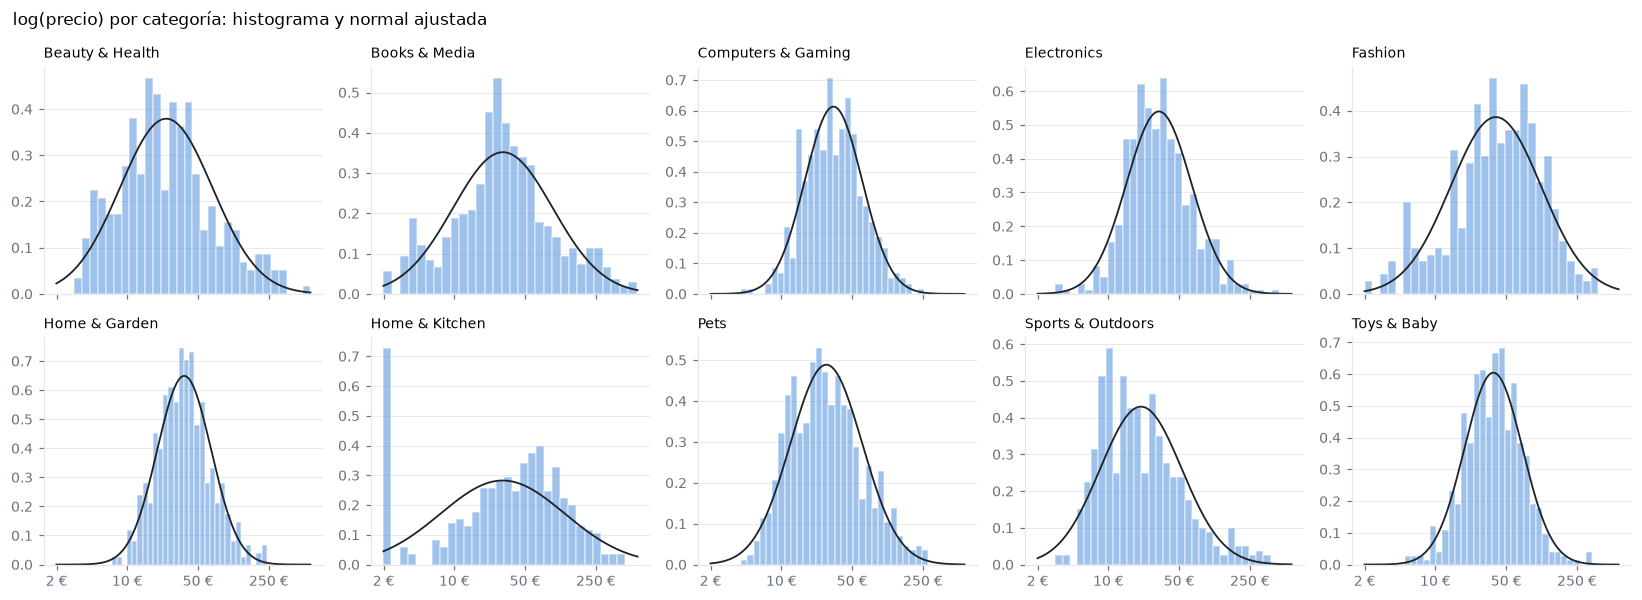

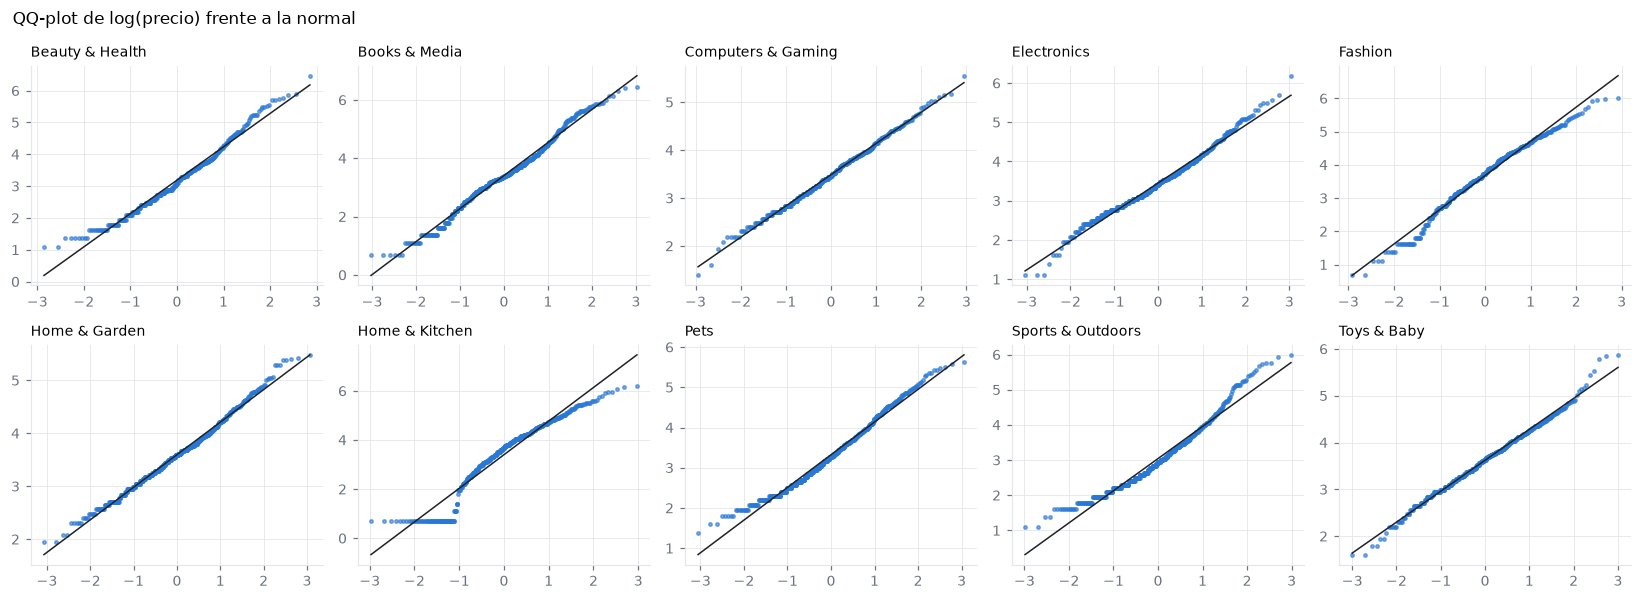

In [8]:
cats = dist.index.tolist()
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5), sharex=True)
xs = np.linspace(base.log_price.min(), base.log_price.max(), 200)
for ax, c in zip(axes.flat, cats):
    l = base.loc[base.category == c, "log_price"]
    ax.hist(l, bins=30, density=True, color=BLUE, alpha=0.45, edgecolor="white")
    ax.plot(xs, stats.norm.pdf(xs, l.mean(), l.std()), color=INK, lw=1.2)
    ax.set_title(c, loc="left", fontsize=9); ax.grid(axis="x", visible=False)
    ax.set_xticks(np.log([2, 10, 50, 250]), ["2 €", "10 €", "50 €", "250 €"])
plt.suptitle("log(precio) por categoría: histograma y normal ajustada", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "logprecio_hist_categoria.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 5.5))
for ax, c in zip(axes.flat, cats):
    l = base.loc[base.category == c, "log_price"]
    (osm, osr), (slope, inter, _) = stats.probplot(l)
    ax.scatter(osm, osr, s=5, color=BLUE, alpha=0.6); ax.plot(osm, slope * osm + inter, color=INK, lw=1)
    ax.set_title(c, loc="left", fontsize=9)
plt.suptitle("QQ-plot de log(precio) frente a la normal", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "logprecio_qq_categoria.png", bbox_inches="tight"); plt.show()

## 3. Consumo: compras orgánicas (`history_events`, 60 días)

Una fila por compra. El precio es el de ese momento.

In [9]:
buys = sql("""
SELECT ts::DateTime64(3) AS ts, user_id::String AS user_id, session_id::String AS session_id,
       product_id::String AS product_id, price_eur::Float64 AS price, device::String AS device, region::String AS region
FROM shop.history_events WHERE event_type = 'purchase'""")
buys["ts"] = pd.to_datetime(buys.ts)
buys = buys.merge(cat[["product_id", "category", "subcategory"]], on="product_id", how="left")
print(f"{len(buys):,} compras · {buys.user_id.nunique():,} usuarios · {buys.session_id.nunique():,} sesiones con compra".replace(",", "."))
buys.head()

548.160 compras · 51.799 usuarios · 464.465 sesiones con compra


,ts,user_id,session_id,product_id,price,device,region,category,subcategory
0,2026-09-15 07:12:03.180,u_6553f3dc,s_27fed594e988,p_c499f9,16.99,android,Andalucía,Electronics,Phone Cases
1,2026-09-15 07:14:35.025,u_1c0c97e8,s_cde0742d4159,p_775816,38.99,android,Aragón,Toys & Baby,Baby Bottles
2,2026-09-15 07:17:33.614,u_7727e226,s_f490a7448015,p_69d40e,18.99,web,Galicia,Fashion,Jeans
3,2026-09-15 07:17:53.792,u_734e7a3f,s_d228aa6031f0,p_9c2b8b,27.99,android,Andalucía,Books & Media,Turntables
4,2026-09-15 07:20:12.791,u_9db90699,s_1bae0ba742f0,p_adc3e6,1.99,ios,País Vasco,Books & Media,E-Readers


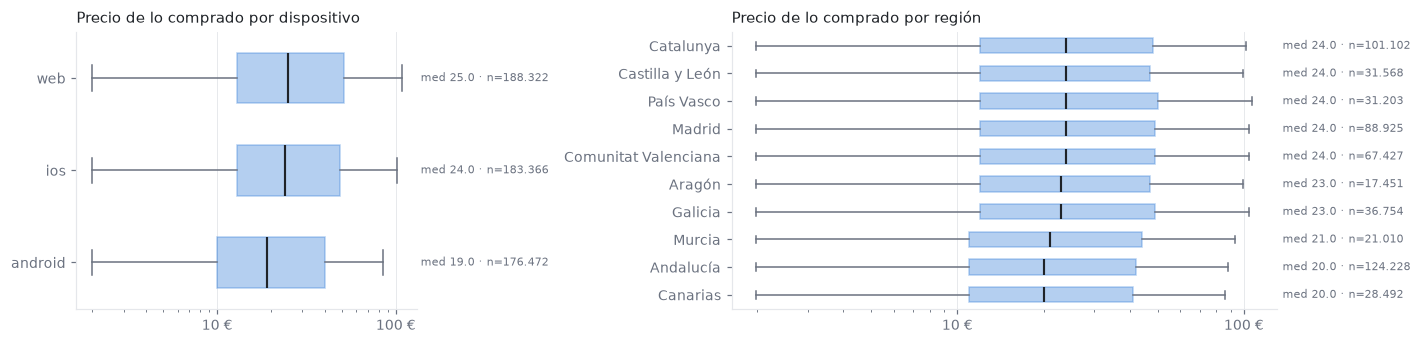

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
boxplot(buys, "device", "price", "Precio de lo comprado por dispositivo", ax=axes[0])
boxplot(buys, "region", "price", "Precio de lo comprado por región", ax=axes[1])
plt.tight_layout(); plt.savefig(FIG / "precio_compra_device_region.png", bbox_inches="tight"); plt.show()

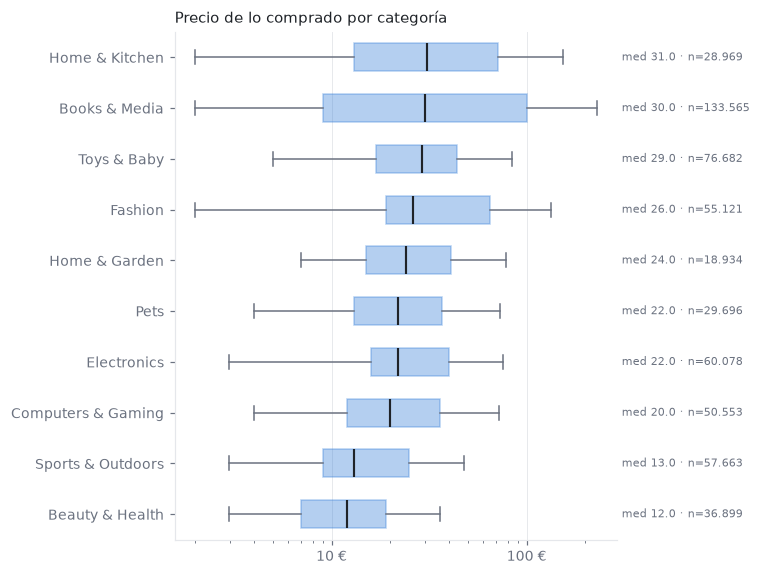

,mediana_catalogo,mediana_comprado,compras,compras_por_producto
category,,,,
Books & Media,29.49,29.99,133565,236.82
Toys & Baby,37.99,28.99,76682,145.51
Electronics,30.99,21.99,60078,101.65
Sports & Outdoors,18.99,12.99,57663,116.49
Fashion,42.49,25.99,55121,135.77
Computers & Gaming,31.99,19.99,50553,115.68
Beauty & Health,21.99,11.99,36899,112.16
Pets,25.99,21.99,29696,47.82
Home & Kitchen,39.99,30.99,28969,60.99


In [11]:
boxplot(buys, "category", "price", "Precio de lo comprado por categoría", fname="precio_compra_categoria.png")
comp = pd.DataFrame({"mediana_catalogo": cat.groupby("category").price.median(),
                     "mediana_comprado": buys.groupby("category").price.median(),
                     "compras": buys.groupby("category").size(),
                     "compras_por_producto": buys.groupby("category").size() / cat.groupby("category").size()}).round(2)
comp.sort_values("compras", ascending=False)

### Gasto por usuario (60 días)

Cada usuario se asigna a su región y dispositivo más frecuentes. Primero comprobamos si los usuarios cambian de región o dispositivo.

In [12]:
u = buys.groupby("user_id").agg(gasto=("price", "sum"), compras=("price", "size"), ticket_medio=("price", "mean"),
                                 n_devices=("device", "nunique"), n_regions=("region", "nunique"))
u["device"] = buys.groupby("user_id").device.agg(lambda s: s.mode().iat[0])
u["region"] = buys.groupby("user_id").region.agg(lambda s: s.mode().iat[0])
print(f"usuarios con más de 1 dispositivo: {(u.n_devices > 1).mean():.1%} · con más de 1 región: {(u.n_regions > 1).mean():.1%}")
u[["gasto", "compras", "ticket_medio"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(1)

usuarios con más de 1 dispositivo: 0.0% · con más de 1 región: 0.0%


,gasto,compras,ticket_medio
count,51799.0,51799.0,51799.0
mean,480.7,10.6,41.8
std,1088.3,18.0,36.0
min,2.0,1.0,2.0
10%,24.0,1.0,13.3
25%,64.0,2.0,20.3
50%,184.0,5.0,31.8
75%,485.0,12.0,50.8
90%,1104.8,24.0,81.6
max,53357.5,482.0,644.0


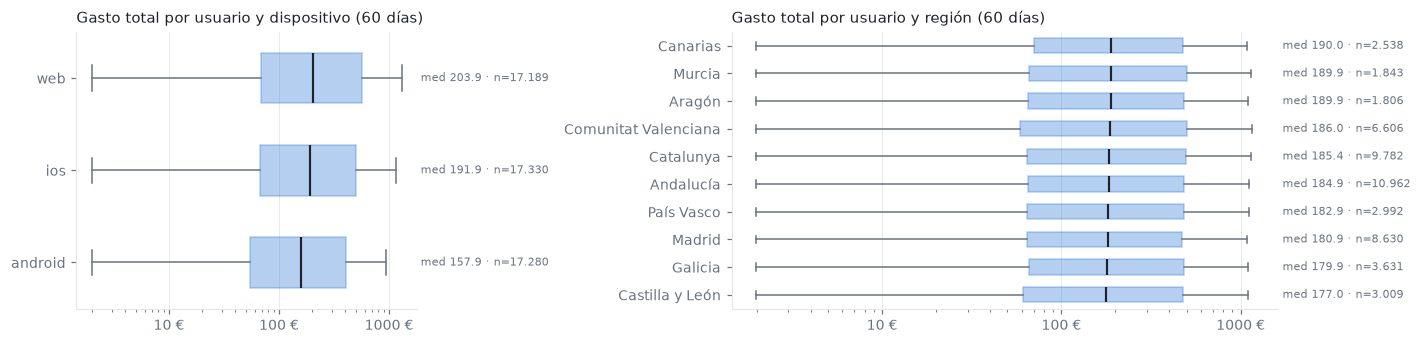

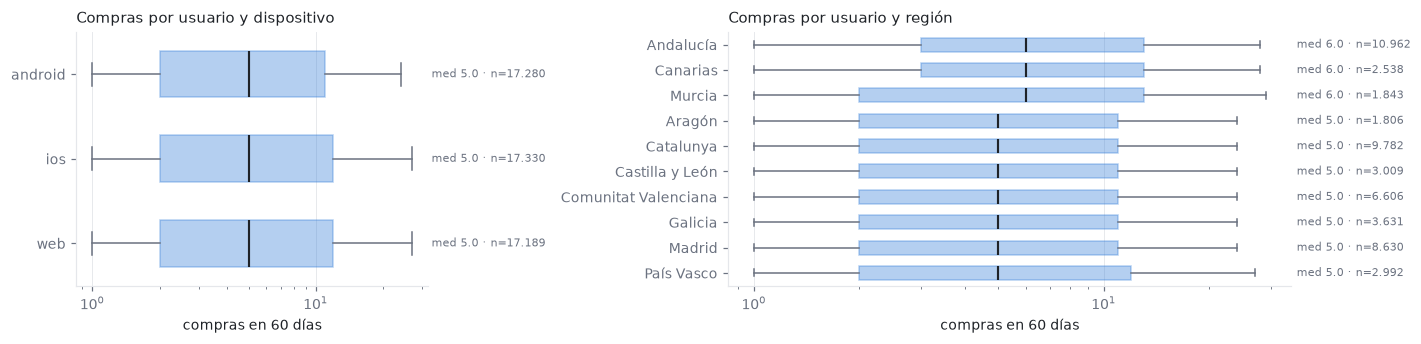

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
boxplot(u, "device", "gasto", "Gasto total por usuario y dispositivo (60 días)", ax=axes[0])
boxplot(u, "region", "gasto", "Gasto total por usuario y región (60 días)", ax=axes[1])
plt.tight_layout(); plt.savefig(FIG / "gasto_usuario_device_region.png", bbox_inches="tight"); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
boxplot(u, "device", "compras", "Compras por usuario y dispositivo", xlabel="compras en 60 días", ax=axes[0])
boxplot(u, "region", "compras", "Compras por usuario y región", xlabel="compras en 60 días", ax=axes[1])
plt.tight_layout(); plt.savefig(FIG / "compras_usuario_device_region.png", bbox_inches="tight"); plt.show()

### Ticket por sesión (sesiones con compra)

artículos por sesión con compra: media 1.18 · 15.2% compran más de 1


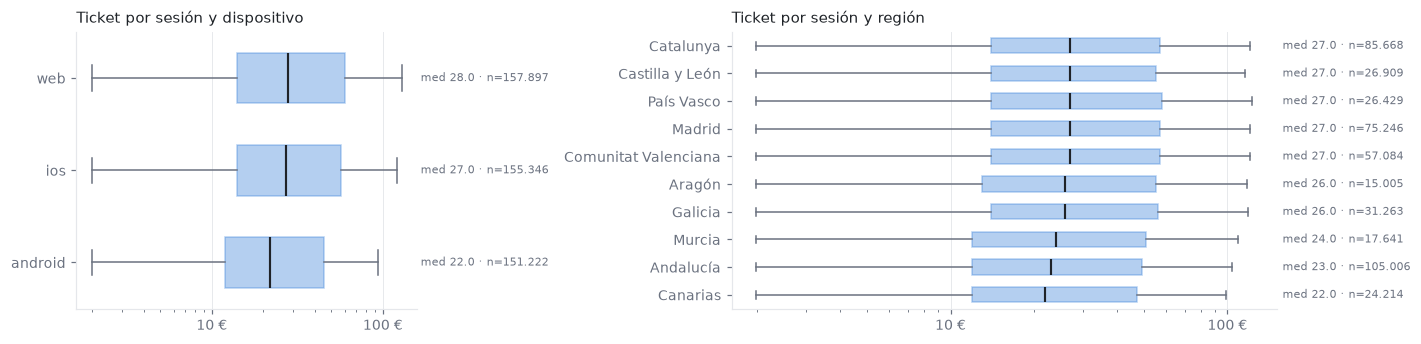

In [14]:
s = buys.groupby("session_id").agg(ticket=("price", "sum"), items=("price", "size"), device=("device", "first"), region=("region", "first"))
print(f"artículos por sesión con compra: media {s['items'].mean():.2f} · {(s['items'] > 1).mean():.1%} compran más de 1")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
boxplot(s, "device", "ticket", "Ticket por sesión y dispositivo", ax=axes[0])
boxplot(s, "region", "ticket", "Ticket por sesión y región", ax=axes[1])
plt.tight_layout(); plt.savefig(FIG / "ticket_sesion_device_region.png", bbox_inches="tight"); plt.show()

In [15]:
tabla = (buys.groupby("region")
           .agg(compras=("price", "size"), usuarios=("user_id", "nunique"), precio_mediano=("price", "median"), precio_medio=("price", "mean"))
           .assign(compras_por_usuario=lambda d: d.compras / d.usuarios)
           .join(u.groupby("region").gasto.median().rename("gasto_mediano_usuario"))
           .sort_values("compras", ascending=False).round(2))
tabla

,compras,usuarios,precio_mediano,precio_medio,compras_por_usuario,gasto_mediano_usuario
region,,,,,,
Andalucía,124228,10962,19.99,41.25,11.33,184.93
Catalunya,101102,9782,23.99,47.01,10.34,185.42
Madrid,88925,8630,23.99,47.71,10.30,180.93
Comunitat Valenciana,67427,6606,23.99,48.01,10.21,185.96
Galicia,36754,3631,22.99,46.46,10.12,179.94
Castilla y León,31568,3009,23.99,46.54,10.49,176.96
País Vasco,31203,2992,23.99,48.39,10.43,182.92
Canarias,28492,2539,19.99,39.99,11.22,189.97
Murcia,21010,1843,20.99,43.64,11.40,189.95


## 4. Compras del carrusel por página y dispositivo (`history_sessions`)

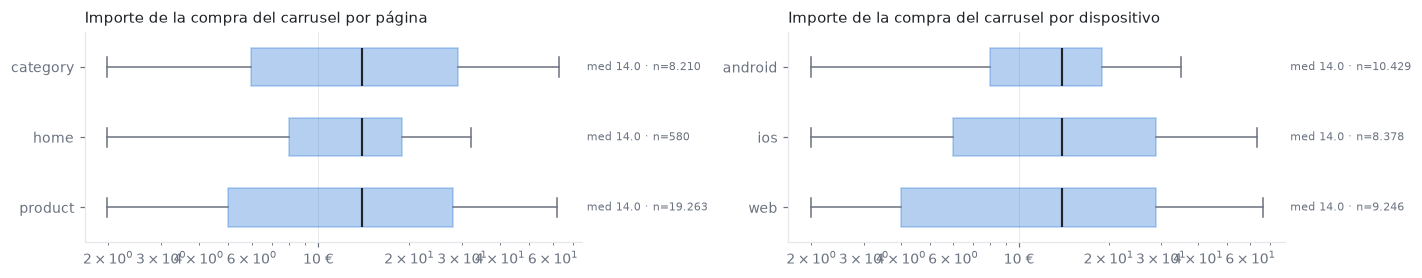

In [16]:
car = sql("""
SELECT context.page::String AS page, context.device::String AS device, context.region::String AS region, revenue_eur::Float64 AS revenue
FROM shop.history_sessions WHERE purchased IS NOT NULL""")
fig, axes = plt.subplots(1, 2, figsize=(13, 2.6))
boxplot(car, "page", "revenue", "Importe de la compra del carrusel por página", ax=axes[0])
boxplot(car, "device", "revenue", "Importe de la compra del carrusel por dispositivo", ax=axes[1])
plt.tight_layout(); plt.savefig(FIG / "carrusel_page_device.png", bbox_inches="tight"); plt.show()

## 5. Cuándo se compra (UTC)

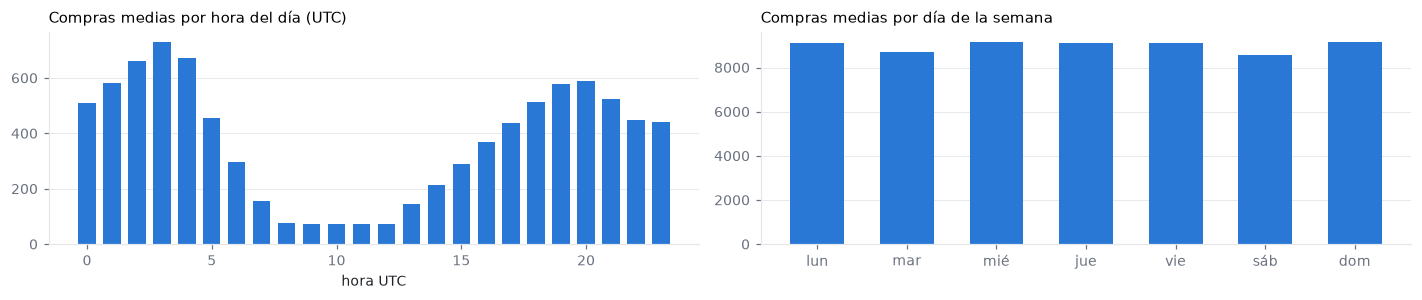

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
h = buys.ts.dt.hour.value_counts().sort_index() / buys.ts.dt.date.nunique()
axes[0].bar(h.index, h.values, color=BLUE, width=0.7); axes[0].set_title("Compras medias por hora del día (UTC)", loc="left", fontsize=10)
axes[0].set_xlabel("hora UTC"); axes[0].grid(axis="x", visible=False)
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
d = buys.groupby(buys.ts.dt.day_of_week).size() / buys.groupby(buys.ts.dt.day_of_week).ts.apply(lambda x: x.dt.date.nunique())
axes[1].bar([dias[i] for i in d.index], d.values, color=BLUE, width=0.6); axes[1].set_title("Compras medias por día de la semana", loc="left", fontsize=10)
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG / "compras_hora_dia.png", bbox_inches="tight"); plt.show()